# Dingo tutorial, part 2: analysing a simulated signal

In part 1 we trained a small neural network. Here we use it.

1. We simulate a signal with known parameters and add noise to it. This is called an *injection*.
2. We ask the network for the posterior distribution of the detector-frame chirp mass $\mathcal{M}_d$ and of the luminosity distance $D_L$.
3. We check and correct the answer with *importance sampling*.
4. We compare with the exact posterior, which in this simple problem can be computed on a grid.

**Run time.** About one minute the first time. The slow steps save their results in the folder `results`,
so that later runs (for example to change a plot) take a few seconds. Delete that folder to compute everything again.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The waveform library (LAL) redirects its messages when it runs inside a notebook.
# This makes waveform generation several times slower, so we switch the redirection off.
# The first two lines only hide the warning that LAL prints about this.
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal
lal.swig_redirect_standard_output_error(False)

from dingo.core.posterior_models.build_model import build_model_from_kwargs
from dingo.gw.inference.sampler import GWComposedSampler
from dingo.gw.injection import Injection
from dingo.gw.noise.asd_dataset import ASDDataset
from dingo.gw.result import Result

import sys
sys.path.append("../figures")
from gwr_style import COLORS, TEXTWIDTH, save_figure, use_book_style

# Fix the random numbers, so that the notebook always gives the same result.
# NumPy draws the noise and the parameters; PyTorch draws the samples from the network.
import torch
np.random.seed(170817)
torch.manual_seed(170817)

# Folder for the results of the slow steps
os.makedirs("results", exist_ok=True)

## Step 1: load the trained network

The file `model_stage_0.pt` contains the network and all the settings used to train it.

In [2]:
model = build_model_from_kwargs(filename="training/model_stage_0.pt", device="cpu", load_training_info=False)

# The settings are stored in a dictionary called "metadata"
detectors = model.metadata["train_settings"]["data"]["detectors"]
print("Detectors:", detectors)
print("Parameters learned by the network:", model.metadata["train_settings"]["data"]["inference_parameters"])

Putting posterior model to device cpu.
Detectors: ['H1', 'L1', 'V1']
Parameters learned by the network: ['chirp_mass', 'luminosity_distance']


## Step 2: simulate a signal

Dingo provides an `Injection` object. We build it from the settings stored in the network.
In this way the simulated data are consistent with the training data: same detectors, same frequencies, same waveform model.
We also tell it which noise curve to use.

In [3]:
injection = Injection.from_posterior_model_metadata(model.metadata)
injection.asd = ASDDataset("training_data/asd_dataset.hdf5", ifos=detectors)

# The prior used in training. Fixed parameters appear as "DeltaFunction".
for name, prior in injection.prior.items():
    print(f"{name:22s} {prior}")

Setting spin_conversion_phase = None. Using phase parameter for conversion to cartesian spins.
Loading dataset from training_data/asd_dataset.hdf5.
mass_1                 Constraint(minimum=10.0, maximum=80.0, name='mass_1', latex_label='$m_1$', unit=None)
mass_2                 Constraint(minimum=10.0, maximum=80.0, name='mass_2', latex_label='$m_2$', unit=None)
chirp_mass             Uniform(minimum=25.0, maximum=35.0, name='chirp_mass', latex_label='$\\mathcal{M}$', unit=None, boundary=None)
mass_ratio             DeltaFunction(peak=0.8, name=None, latex_label=None, unit=None)
chi_1                  DeltaFunction(peak=0.0, name=None, latex_label=None, unit=None)
chi_2                  DeltaFunction(peak=0.0, name=None, latex_label=None, unit=None)
theta_jn               DeltaFunction(peak=0.5, name=None, latex_label=None, unit=None)
phase                  DeltaFunction(peak=0.0, name=None, latex_label=None, unit=None)
luminosity_distance    Uniform(minimum=1000.0, maximum=3000.0, na

We choose the two free parameters ourselves. They must lie inside the prior used in training.
All the other parameters take their fixed values.

In [4]:
# Start from a random draw from the prior: this fills in all the fixed parameters
true_parameters = injection.prior.sample()

# Then choose the two free parameters
true_parameters["chirp_mass"] = 34.85            # solar masses
true_parameters["luminosity_distance"] = 2500.0  # megaparsec

# Simulated data: signal + noise in each detector
data = injection.injection(true_parameters)

# The signal alone, without noise, for the plot below
signal_only = injection.signal(true_parameters)

### How loud is the signal?

The optimal signal-to-noise ratio (SNR) of a signal $h$ in a detector with noise amplitude spectral density (ASD) $\sqrt{S_n}$ is

$$\rho^2 = 4\,\Delta f \sum_k \frac{|\tilde h(f_k)|^2}{S_n(f_k)}.$$

For several detectors, the squares of the SNRs add up.

In [5]:
domain = injection.data_domain
frequencies = domain()
delta_f = frequencies[1] - frequencies[0]
in_band = frequencies >= 20.0  # the analysis uses frequencies above 20 Hz

snr_squared = 0.0
for detector in detectors:
    h = signal_only["waveform"][detector]
    asd = data["asds"][detector]
    snr_squared_detector = 4 * delta_f * np.sum(np.abs(h[in_band]) ** 2 / asd[in_band] ** 2)
    print(f"SNR in {detector}: {np.sqrt(snr_squared_detector):.1f}")
    snr_squared += snr_squared_detector
print(f"Network SNR: {np.sqrt(snr_squared):.1f}")

SNR in H1: 12.0
SNR in L1: 15.2
SNR in V1: 6.1
Network SNR: 20.3


### A picture of the data

We plot the data in the frequency domain for one detector, Virgo.
To compare the signal with the noise, we multiply the amplitude of the data by $2\sqrt{\Delta f}$:
with this factor, pure noise scatters around the ASD curve.

Figure saved to output/fig_injection.pdf


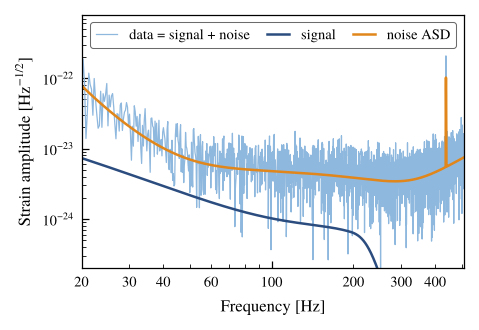

In [6]:
detector = "V1"
scale = 2 * np.sqrt(delta_f)

use_book_style()  # make sure the style of the book is active
fig, ax = plt.subplots(figsize=(0.75 * TEXTWIDTH, 0.5 * TEXTWIDTH))
ax.loglog(frequencies[in_band], scale * np.abs(data["waveform"][detector][in_band]),
          color=COLORS["lightblue"], lw=0.6, label="data = signal + noise")
ax.loglog(frequencies[in_band], scale * np.abs(signal_only["waveform"][detector][in_band]),
          color=COLORS["blue"], label="signal")
ax.loglog(frequencies[in_band], data["asds"][detector][in_band],
          color=COLORS["orange"], label="noise ASD")
ax.set_xlim(20, 512)
ax.set_ylim(2e-25, 8e-22)  # some empty space at the top, for the legend
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel(r"Strain amplitude [Hz$^{-1/2}$]")
# The legend goes at the top, on one row, where it does not cover the signal
ax.legend(loc="upper center", ncol=3, columnspacing=1.2, handlelength=1.5)

save_figure(fig, "fig_injection.pdf")
plt.show()

The signal (dark blue) is below the noise curve (orange) at all frequencies. In the data (light blue) it is hard to see by eye.
It can still be measured, because its SNR builds up over many frequencies.

## Step 3: ask the network

We build a *sampler* from the network and the data, and draw 50 000 samples.
Each sample is a pair (chirp mass, distance) drawn from the distribution $q(\theta|d)$ predicted by the network.
This takes about a second.

In [7]:
sampler = GWComposedSampler.from_model(model, data)
sampler.run_sampler(num_samples=50_000, batch_size=10_000)
result = sampler.to_result()

# The samples are stored in a table
result.samples[["chirp_mass", "luminosity_distance", "log_prob"]].head()

,chirp_mass,luminosity_distance,log_prob
0,34.939327,2721.815674,-5.377123
1,34.902203,2550.110840,-3.519720
2,34.935966,2790.524902,-6.096550
3,34.891785,2732.108887,-4.621371
4,34.840664,2528.966064,-4.919979


The column `log_prob` is the logarithm of $q(\theta|d)$ for each sample. We need it in the next step.

## Step 4: importance sampling

The network gives an approximation of the posterior. Importance sampling tells us how good it is, and corrects it.
Each sample receives a weight

$$w_i = \frac{\mathcal{L}(d|\theta_i)\,\pi(\theta_i)}{q(\theta_i|d)},$$

where $\mathcal{L}$ is the likelihood and $\pi$ the prior. Samples that the network proposed too often get a small weight, and vice versa.
If the network were perfect, all weights would be equal.

To compute the likelihood, Dingo needs the full set of parameters. The fixed ones are filled in automatically.

In [8]:
result_file = "results/injection_result.hdf5"

if not os.path.exists(result_file):
    # The slow step: about one minute
    result.importance_sample()
    # Save the samples and their weights
    result.to_file(result_file)
else:
    # The result was saved by an earlier run of this notebook: read it instead of computing it again
    result = Result(file_name=result_file)

result.print_summary()

Loading dataset from results/injection_result.hdf5.
Number of samples: 50000
Log(evidence): -5966.118 +- 0.010
Effective samples 8752.9: (Sample efficiency = 17.51%)


The **sample efficiency** is the fraction of samples that are effectively useful after weighting.
The summary also gives the number of effective samples and the *evidence*, used to compare models.

For this signal the efficiency is about 17%. The network is not very accurate here: the signal lies close to the upper edge of the chirp-mass prior, where the network is at its worst (see part 3).
This is not a problem. We drew 50 000 samples, so we still have about 9000 effective samples.
A common requirement is at least 5000 effective samples. If there are fewer, simply draw more samples from the network.

From now on, the weights must always be used. For example, the mean and standard deviation of each parameter:

In [9]:
weights = result.samples["weights"].to_numpy()
for name in ["chirp_mass", "luminosity_distance"]:
    values = result.samples[name].to_numpy()
    mean = np.average(values, weights=weights)
    std = np.sqrt(np.average((values - mean) ** 2, weights=weights))
    print(f"{name:20s} = {mean:8.2f} +/- {std:.2f}    (true value: {true_parameters[name]:.2f})")

chirp_mass           =    34.87 +/- 0.03    (true value: 34.85)
luminosity_distance  =  2583.13 +/- 130.52    (true value: 2500.00)


## Step 5: compare with the exact posterior

With only two free parameters we can afford a brute-force check.
We evaluate likelihood times prior on a grid of 80 x 80 points that covers the region where the posterior is.
This gives the exact posterior, with no neural network involved.

(With the 11 or 15 parameters of a real analysis this is impossible: a grid with 80 points per parameter would have $80^{15}$ points.)

In [10]:
samples_mc = result.samples["chirp_mass"].to_numpy()
samples_dl = result.samples["luminosity_distance"].to_numpy()

# Weighted mean and standard deviation of the two parameters
mean_mc = np.average(samples_mc, weights=weights)
std_mc = np.sqrt(np.average((samples_mc - mean_mc) ** 2, weights=weights))
mean_dl = np.average(samples_dl, weights=weights)
std_dl = np.sqrt(np.average((samples_dl - mean_dl) ** 2, weights=weights))

grid_file = "results/exact_posterior_grid.npz"

if not os.path.exists(grid_file):
    # The grid covers 5 standard deviations on each side of the mean (but stays inside the prior)
    mc_grid = np.linspace(max(mean_mc - 5 * std_mc, 25), min(mean_mc + 5 * std_mc, 35), 80)
    dl_grid = np.linspace(max(mean_dl - 5 * std_dl, 1000), min(mean_dl + 5 * std_dl, 3000), 80)
    mc_mesh, dl_mesh = np.meshgrid(mc_grid, dl_grid)

    # A table with one row per grid point. Start from the fixed parameters, then set the two free ones.
    grid_points = pd.DataFrame({name: np.full(mc_mesh.size, value) for name, value in true_parameters.items()})
    grid_points["chirp_mass"] = mc_mesh.ravel()
    grid_points["luminosity_distance"] = dl_mesh.ravel()

    # The likelihood object was created by Dingo during importance sampling
    log_likelihood = result.likelihood.log_likelihood_multi(grid_points, num_processes=1)

    # The prior is uniform in both parameters, so the posterior is proportional to the likelihood
    posterior_grid = np.exp(log_likelihood - log_likelihood.max()).reshape(mc_mesh.shape)
    posterior_grid /= posterior_grid.sum()

    np.savez(grid_file, mc_grid=mc_grid, dl_grid=dl_grid, posterior_grid=posterior_grid)

# Read the grid from the file
saved = np.load(grid_file)
mc_grid, dl_grid, posterior_grid = saved["mc_grid"], saved["dl_grid"], saved["posterior_grid"]

### The figure

We compare three things:

* the samples from Dingo alone (no weights);
* the samples after importance sampling (with weights);
* the exact posterior from the grid.

The large panel shows the two-dimensional posterior. The contours contain 50% and 90% of the probability.
For Dingo alone, the dots are the samples outside the 90% contour.
The small panels show the posterior of each parameter separately.

Figure saved to output/fig_posterior.pdf


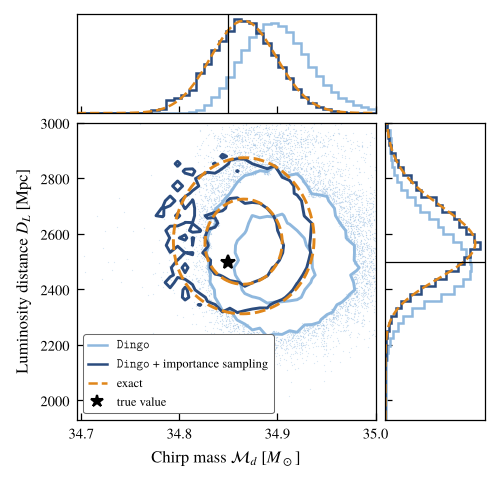

In [11]:
def contour_levels(density, fractions=(0.9, 0.5)):
    """Density values whose contours enclose the given fractions of the total probability."""
    sorted_density = np.sort(density.ravel())[::-1]
    cumulative = np.cumsum(sorted_density) / sorted_density.sum()
    return [sorted_density[np.searchsorted(cumulative, fraction)] for fraction in fractions]


def histogram_2d(x, y, weights=None):
    """Two-dimensional histogram of the samples on the same grid used for the exact posterior."""
    mc_edges = np.linspace(mc_grid[0], mc_grid[-1], 41)
    dl_edges = np.linspace(dl_grid[0], dl_grid[-1], 41)
    histogram, _, _ = np.histogram2d(x, y, bins=[mc_edges, dl_edges], weights=weights)
    mc_centres = 0.5 * (mc_edges[1:] + mc_edges[:-1])
    dl_centres = 0.5 * (dl_edges[1:] + dl_edges[:-1])
    return mc_centres, dl_centres, histogram.T


use_book_style()  # make sure the style of the book is active
fig = plt.figure(figsize=(0.8 * TEXTWIDTH, 0.8 * TEXTWIDTH))
grid = fig.add_gridspec(2, 2, width_ratios=[3, 1], height_ratios=[1, 3], hspace=0.05, wspace=0.05)
ax_main = fig.add_subplot(grid[1, 0])
ax_top = fig.add_subplot(grid[0, 0], sharex=ax_main)
ax_right = fig.add_subplot(grid[1, 1], sharey=ax_main)

# --- two-dimensional posterior ---
x, y, density = histogram_2d(samples_mc, samples_dl)
levels = contour_levels(density)
ax_main.contour(x, y, density, levels=levels, colors=COLORS["lightblue"], linewidths=1.4)

# For Dingo alone we also draw, as dots, the samples that fall outside the outer (90%) contour.
# To find them, we look up the density of the histogram bin that contains each sample.
width_mc, width_dl = x[1] - x[0], y[1] - y[0]
bin_mc = np.clip(np.floor((samples_mc - mc_grid[0]) / width_mc).astype(int), 0, len(x) - 1)
bin_dl = np.clip(np.floor((samples_dl - dl_grid[0]) / width_dl).astype(int), 0, len(y) - 1)
outside = density[bin_dl, bin_mc] < levels[0]
# The dots are small and pale, so that the contours remain clearly visible.
ax_main.plot(samples_mc[outside], samples_dl[outside], ".", ms=1.2, mew=0, color=COLORS["lightblue"], alpha=0.35,
             rasterized=True, zorder=0)
x, y, density = histogram_2d(samples_mc, samples_dl, weights)
ax_main.contour(x, y, density, levels=contour_levels(density), colors=COLORS["blue"], linewidths=1.4)
ax_main.contour(mc_grid, dl_grid, posterior_grid, levels=contour_levels(posterior_grid),
                colors=COLORS["orange"], linewidths=1.4, linestyles="--")
ax_main.plot(true_parameters["chirp_mass"], true_parameters["luminosity_distance"], marker="*", ms=7, color="k")
ax_main.set_xlim(mc_grid[0], mc_grid[-1])
ax_main.set_ylim(dl_grid[0], dl_grid[-1])
ax_main.set_xlabel(r"Chirp mass $\mathcal{M}_d$ [$M_\odot$]")
ax_main.set_ylabel(r"Luminosity distance $D_L$ [Mpc]")

# --- one-dimensional posteriors ---
bins_mc = np.linspace(mc_grid[0], mc_grid[-1], 41)
bins_dl = np.linspace(dl_grid[0], dl_grid[-1], 41)
ax_top.hist(samples_mc, bins=bins_mc, density=True, histtype="step", color=COLORS["lightblue"], lw=1.2)
ax_top.hist(samples_mc, bins=bins_mc, density=True, histtype="step", color=COLORS["blue"], lw=1.2, weights=weights)
exact_mc = posterior_grid.sum(axis=0)
ax_top.plot(mc_grid, exact_mc / (exact_mc.sum() * (mc_grid[1] - mc_grid[0])), color=COLORS["orange"], ls="--")
ax_top.axvline(true_parameters["chirp_mass"], color="k", lw=0.6)

ax_right.hist(samples_dl, bins=bins_dl, density=True, histtype="step", color=COLORS["lightblue"], lw=1.2,
              orientation="horizontal")
ax_right.hist(samples_dl, bins=bins_dl, density=True, histtype="step", color=COLORS["blue"], lw=1.2, weights=weights,
              orientation="horizontal")
exact_dl = posterior_grid.sum(axis=1)
ax_right.plot(exact_dl / (exact_dl.sum() * (dl_grid[1] - dl_grid[0])), dl_grid, color=COLORS["orange"], ls="--")
ax_right.axhline(true_parameters["luminosity_distance"], color="k", lw=0.6)

# hide the tick labels of the small panels
ax_top.tick_params(labelbottom=False, labelleft=False, left=False)
ax_right.tick_params(labelleft=False, labelbottom=False, bottom=False)

# legend (the name of the code is written in a monospace font)
ax_main.plot([], [], color=COLORS["lightblue"], label=r"$\mathtt{Dingo}$")
ax_main.plot([], [], color=COLORS["blue"], label=r"$\mathtt{Dingo}$ + importance sampling")
ax_main.plot([], [], color=COLORS["orange"], ls="--", label="exact")
ax_main.plot([], [], marker="*", ms=6, color="k", ls="none", label="true value")
ax_main.legend(loc="lower left", fontsize=6, handlelength=1.5)

save_figure(fig, "fig_posterior.pdf")
plt.show()

Dingo alone (light blue) finds the right region, but its distribution is shifted and somewhat too broad. This is why the efficiency is modest.
Importance sampling corrects it: the weighted samples (dark blue) fall onto the exact posterior (orange).
The dark blue contours are a little ragged on the left, where the network proposed few samples.

The chirp mass is measured to about 0.1%. The distance is more uncertain (about 5%), because it is determined only by the amplitude of the signal.

In part 3 we repeat this analysis for many signals, to test the network over the whole prior.